## PCA Explanation

C:\tools\anaconda3\envs\work\Lib\site-packages\sklearn\utils\_param_validation.py:14: UserWarning: A NumPy version >=1.22.4 and <2.3.0 is required for this version of SciPy (detected version 2.3.5)
  from scipy.sparse import csr_matrix, issparse



--- Pre-PCA Variances ---
Variance along x1: 135.0000
Variance along x2: 147.1643
Overall (Total) Variance: 282.1643

--- Post-PCA Variances ---
Variance along PC1: 276.2991
Variance along PC2: 5.8652
Overall (Total) Variance: 282.1643

--- Principal Component Linear Expressions ---
PC1 = (0.6910) * (x1 - 29.7500) + (0.7228) * (x2 - 29.7980)
PC2 = (0.7228) * (x1 - 29.7500) - (0.6910) * (x2 - 29.7980)

Saved data to 'PCA-explanation-original-data.xlsx' and 'PCA-explanation-post-PC-data.xlsx'.


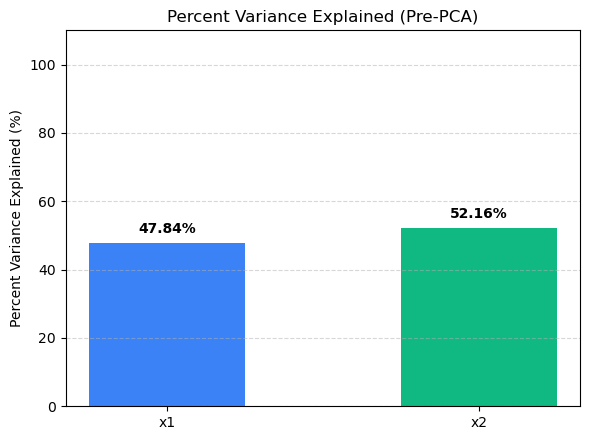

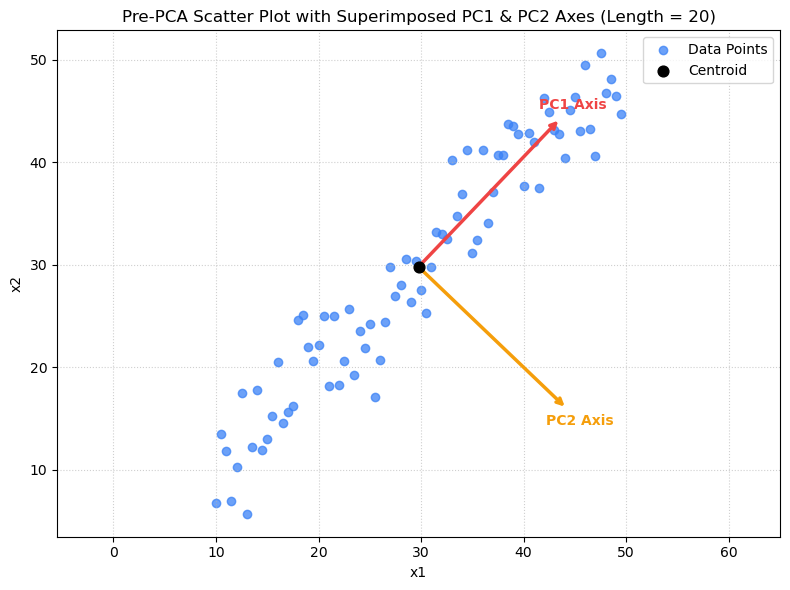

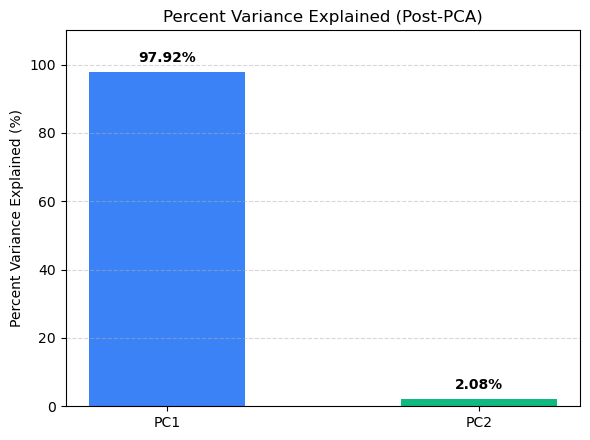

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# ---------------------------------------------------------
# 1. Data Generation & Initial Scatter Plot
# ---------------------------------------------------------
np.random.seed(123)
x1 = np.arange(10, 50, 0.5)
noise = np.random.normal(0, 3, size=len(x1))
x2 = x1 + noise
X = np.column_stack((x1, x2))

# Create the initial pre-PCA scatter plot
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], alpha=0.75, color='#3b82f6', label='Data Points')
plt.xlabel('x1')
plt.ylabel('x2')

# ---------------------------------------------------------
# 2. Helper Functions for Variance & PCA Analysis
# ---------------------------------------------------------
def compute_and_print_variances(data_matrix, axis_names, stage_title):
    """
    Calculates sample variance along each axis and total overall variance,
    prints the results, and returns the variance values.
    """
    variances = np.var(data_matrix, axis=0, ddof=1)
    overall_variance = np.sum(variances)
    
    print(f"\n--- {stage_title} ---")
    for name, var in zip(axis_names, variances):
        print(f"Variance along {name}: {var:.4f}")
    print(f"Overall (Total) Variance: {overall_variance:.4f}")
    
    return variances, overall_variance


def plot_variance_bar_chart(variances, axis_names, chart_title):
    """
    Plots a vertical bar chart displaying the percentage of total variance
    explained by each axis.
    """
    total_var = np.sum(variances)
    percent_variances = (variances / total_var) * 100.0

    plt.figure(figsize=(6, 4.5))
    bars = plt.bar(axis_names, percent_variances, color=['#3b82f6', '#10b981'], width=0.5)
    plt.ylabel('Percent Variance Explained (%)')
    plt.title(chart_title)
    plt.ylim(0, 110)
    plt.grid(axis='y', linestyle='--', alpha=0.5)

    # Annotate exact percentages above each bar
    for bar, pct in zip(bars, percent_variances):
        plt.text(
            bar.get_x() + bar.get_width() / 2.0,
            bar.get_height() + 2.0,
            f"{pct:.2f}%",
            ha='center',
            va='bottom',
            fontweight='bold'
        )
    plt.tight_layout()


def superimpose_pca_axes(pca_model, mean_vec, axis_length=20):
    """
    Superimposes the PC1 and PC2 eigenvectors starting from the data centroid
    with a fixed length of 20 units onto the currently active pre-PCA scatter plot.
    """
    colors = ['#ef4444', '#f59e0b']
    labels = ['PC1 Axis', 'PC2 Axis']

    # Mark the centroid of the data
    plt.scatter(mean_vec[0], mean_vec[1], color='black', s=60, zorder=5, label='Centroid')

    for i, vector in enumerate(pca_model.components_):
        # Unit eigenvector scaled to the desired fixed length (20 units)
        v = vector * axis_length
        plt.annotate(
            '',
            xy=mean_vec + v,
            xytext=mean_vec,
            arrowprops=dict(arrowstyle='->', linewidth=2.5, color=colors[i]),
            zorder=4
        )
        # Add axis label just beyond the arrowhead
        label_pos = mean_vec + vector * (axis_length + 1.8)
        plt.text(
            label_pos[0],
            label_pos[1],
            labels[i],
            color=colors[i],
            fontweight='bold',
            ha='center',
            va='center'
        )

    # Ensure equal aspect ratio so PC1 and PC2 appear truly orthogonal
    plt.axis('equal')
    plt.title('Pre-PCA Scatter Plot with Superimposed PC1 & PC2 Axes (Length = 20)')
    plt.legend()
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.tight_layout()


def print_pc_expressions(pca_model):
    """
    Prints the linear combination expressions defining PC1 and PC2
    in terms of PCA loadings and mean-centered original features (x1, x2).
    """
    loadings = pca_model.components_
    means = pca_model.mean_
    
    print("\n--- Principal Component Linear Expressions ---")
    for idx, pc_name in enumerate(['PC1', 'PC2']):
        l1, l2 = loadings[idx, 0], loadings[idx, 1]
        sign = "+" if l2 >= 0 else "-"
        print(
            f"{pc_name} = ({l1:.4f}) * (x1 - {means[0]:.4f}) "
            f"{sign} ({abs(l2):.4f}) * (x2 - {means[1]:.4f})"
        )


# ---------------------------------------------------------
# 3. Execute Workflow
# ---------------------------------------------------------
try:
    # 1. Pre-PCA variances along x1 and x2
    pre_variances, _ = compute_and_print_variances(
        X, ['x1', 'x2'], "Pre-PCA Variances"
    )

    # 2. Vertical bar chart of pre-PCA percent variance explained
    plot_variance_bar_chart(
        pre_variances, ['x1', 'x2'], "Percent Variance Explained (Pre-PCA)"
    )

    # Switch back to Figure 1 (the pre-PCA scatter plot) before superimposing axes
    plt.figure(1)

    # 3. Perform PCA and superimpose PC1 & PC2 axes starting at centroid (length = 20)
    pca = PCA(n_components=2)
    X_pca = pca.fit_transform(X)
    superimpose_pca_axes(pca, pca.mean_, axis_length=20)

    # 4. Post-PCA variances along PC1 and PC2
    post_variances, _ = compute_and_print_variances(
        X_pca, ['PC1', 'PC2'], "Post-PCA Variances"
    )

    # 5. Vertical bar chart of post-PCA percent variance explained
    plot_variance_bar_chart(
        post_variances, ['PC1', 'PC2'], "Percent Variance Explained (Post-PCA)"
    )

    # 6. Print linear equations for PC1 and PC2 using loadings and x1, x2
    print_pc_expressions(pca)

    # 7. Save original and post-PCA data to Excel files
    pd.DataFrame(X, columns=['x1', 'x2']).to_excel(
        'PCA-explanation-original-data.xlsx', index=False
    )
    pd.DataFrame(X_pca, columns=['PC1', 'PC2']).to_excel(
        'PCA-explanation-post-PC-data.xlsx', index=False
    )
    print("\nSaved data to 'PCA-explanation-original-data.xlsx' and 'PCA-explanation-post-PC-data.xlsx'.")

    # Display all generated figures
    plt.show()

except Exception as e:
    print(f"An error occurred during PCA analysis: {e}")